<a href="https://colab.research.google.com/github/AntonySSk/Machine_Learning/blob/dev/%D0%9B%D0%A04_%D0%A8%D0%BA%D0%BE%D0%BB%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [9]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_file_path = os.path.join(path, 'CarPrice_Assignment.csv')

df = pd.read_csv(csv_file_path)

print("=== ПЕРВИННИЙ АНАЛІЗ ДАНИХ ===")

print(f"\n• Кількість об'єктів (рядків): {df.shape[0]}")
print(f"• Кількість ознак (стовпців): {df.shape[1]}")

print("\n• Назви стовпців у датасеті:")
print(list(df.columns))

print("\n• Типи даних для кожного стовпця:")
print(df.dtypes)

target_column = 'price'
print(f"\n• Цільова змінна: '{target_column}' (ціна автомобіля)")

print("\n• Основні статистичні характеристики числових ознак:")
display(df.describe())

print("\n• Перші 5 рядків датасету:")
display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.
=== ПЕРВИННИЙ АНАЛІЗ ДАНИХ ===

• Кількість об'єктів (рядків): 205
• Кількість ознак (стовпців): 26

• Назви стовпців у датасеті:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

• Типи даних для кожного стовпця:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           ob

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



• Перші 5 рядків датасету:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Первинний огляд датасету дозволив визначити його розмірність, типи ознак і цільову змінну price, що підтвердило коректність завантаження даних та готовність до подальшого аналізу.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [10]:
from sklearn.model_selection import train_test_split

X_full = df.drop(columns=['car_ID'])
y_full = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

print("=== ПЕРЕВІРКА ЯКОСТІ ДАНИХ ===")

train_df = X_train.copy()
train_df['price'] = y_train

missing_values = train_df.isnull().sum()
print("\n• Пропущені значення:")
print(missing_values[missing_values > 0])
if missing_values.sum() == 0:
    print("  (Пропущених значень не виявлено)")

duplicates_count = train_df.duplicated().sum()
print(f"\n• Кількість повних дублікатів: {duplicates_count}")

print("\n• Кількість унікальних значень:")
unique_counts = train_df.nunique()
display(unique_counts)

=== ПЕРЕВІРКА ЯКОСТІ ДАНИХ ===

• Пропущені значення:
Series([], dtype: int64)
  (Пропущених значень не виявлено)

• Кількість повних дублікатів: 0

• Кількість унікальних значень:


,0
symboling,6
CarName,124
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,47
carlength,65


Аналіз навчальної вибірки (з попереднім виключенням car_ID) показав відсутність пропусків і повних дублікатів, а також дозволив оцінити унікальні значення ознак для їх майбутнього кодування та масштабування.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [11]:
train_car_ids = df.loc[X_train.index, 'car_ID']
test_car_ids = df.loc[X_test.index, 'car_ID']

if 'car_ID' in X_train.columns:
    X_train = X_train.drop(columns=['car_ID'])
if 'car_ID' in X_test.columns:
    X_test = X_test.drop(columns=['car_ID'])

print("=== РОБОТА З car_ID ВИКОНАНА ===")
print(f"Кількість збережених ID для навчальної вибірки: {len(train_car_ids)}")
print(f"Кількість збережених ID для тестової вибірки: {len(test_car_ids)}")
print("Ознаку car_ID успішно відокремлено від предикторів.")

=== РОБОТА З car_ID ВИКОНАНА ===
Кількість збережених ID для навчальної вибірки: 164
Кількість збережених ID для тестової вибірки: 41
Ознаку car_ID успішно відокремлено від предикторів.


Ідентифікатор car_ID було збережено окремо для подальшої ідентифікації автомобілів у результатах прогнозування, а з набору ознак для навчання моделей його повністю виключено.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


=== КОЕФІЦІЄНТИ АСИМЕТРІЇ (TRAIN) ===


,0
compressionratio,2.737494
enginesize,2.049555
price,1.745180
horsepower,1.546398
carwidth,1.014691
wheelbase,1.011049
curbweight,0.712433
citympg,0.419117
highwaympg,0.289597
carlength,0.236735



Ознака з найбільш вираженою асиметрією: 'compressionratio' (коефіцієнт асиметрії: 2.74)


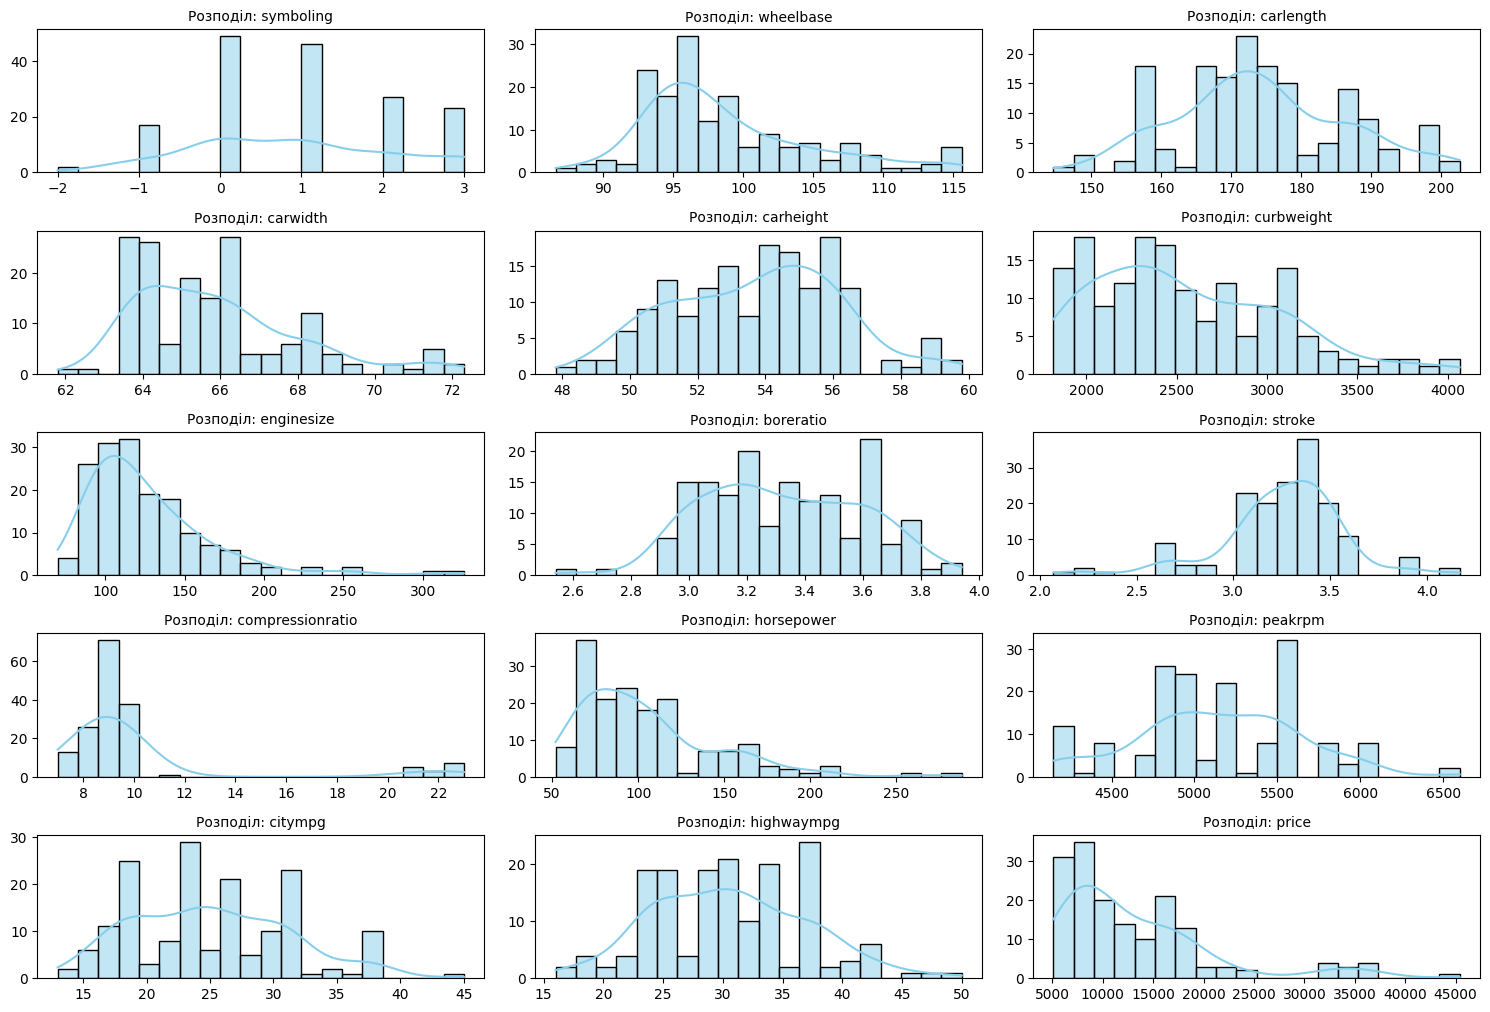

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

skewness = X_train[numeric_cols].skew().sort_values(ascending=False)

print("=== КОЕФІЦІЄНТИ АСИМЕТРІЇ (TRAIN) ===")
display(skewness)

most_skewed = skewness.abs().idxmax()
print(f"\nОзнака з найбільш вираженою асиметрією: '{most_skewed}' (коефіцієнт асиметрії: {skewness[most_skewed]:.2f})")

plt.figure(figsize=(15, 12))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols) // 3 + 1, 3, i)
    sns.histplot(X_train[col], kde=True, color='skyblue', bins=20)
    plt.title(f'Розподіл: {col}', fontsize=10)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

Дослідження числових ознак навчальної вибірки за допомогою гістограм та коефіцієнтів асиметрії показало наявність правобічної асиметрії у низки характеристик, які потребуватимуть подальшої уваги при обробці викидів.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [13]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

train_car_ids = df.loc[X_train.index, 'car_ID']
test_car_ids = df.loc[X_test.index, 'car_ID']

if 'car_ID' in X_train.columns:
    X_train = X_train.drop(columns=['car_ID'])
if 'car_ID' in X_test.columns:
    X_test = X_test.drop(columns=['car_ID'])

print(f"Розмір навчальної вибірки (X_train): {X_train.shape}")
print(f"Розмір тестової вибірки (X_test): {X_test.shape}")
print(f"Кількість збережених ID для train: {len(train_car_ids)}")
print(f"Кількість збережених ID для test: {len(test_car_ids)}")

Розмір навчальної вибірки (X_train): (164, 24)
Розмір тестової вибірки (X_test): (41, 24)
Кількість збережених ID для train: 164
Кількість збережених ID для test: 41


Цільову змінну price відокремлено від ознак, а дані успішно розділено на навчальну (80%) та тестову (20%) вибірки з гарантованою відтворюваністю, при цьому ідентифікатори car_ID збережено окремо для подальшого аналізу.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [14]:
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

outlier_counts = {}
for col in numeric_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)]
    outlier_counts[col] = len(outliers)

    X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
    X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

print("=== КІЛЬКІСТЬ ПОТЕНЦІЙНИХ ВИКИДІВ ЗА IQR (TRAIN) ===")
for col, count in outlier_counts.items():
    print(f"• {col}: {count}")

print("\nМежі успішно розраховано за train та застосовано для кліпінгу на train і test вибірках.")

=== КІЛЬКІСТЬ ПОТЕНЦІЙНИХ ВИКИДІВ ЗА IQR (TRAIN) ===
• symboling: 0
• wheelbase: 6
• carlength: 0
• carwidth: 10
• carheight: 0
• curbweight: 0
• enginesize: 7
• boreratio: 1
• stroke: 16
• compressionratio: 20
• horsepower: 7
• peakrpm: 2
• citympg: 0
• highwaympg: 1

Межі успішно розраховано за train та застосовано для кліпінгу на train і test вибірках.


За допомогою методу IQR на основі навчальної вибірки визначено кількість потенційних викидів для кожної числової ознаки. Застосовано обмеження (кліпінг) крайніх значень у межах допустимого діапазону для train та test вибірок без видалення рядків, що дозволило зберегти розмір набору даних.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


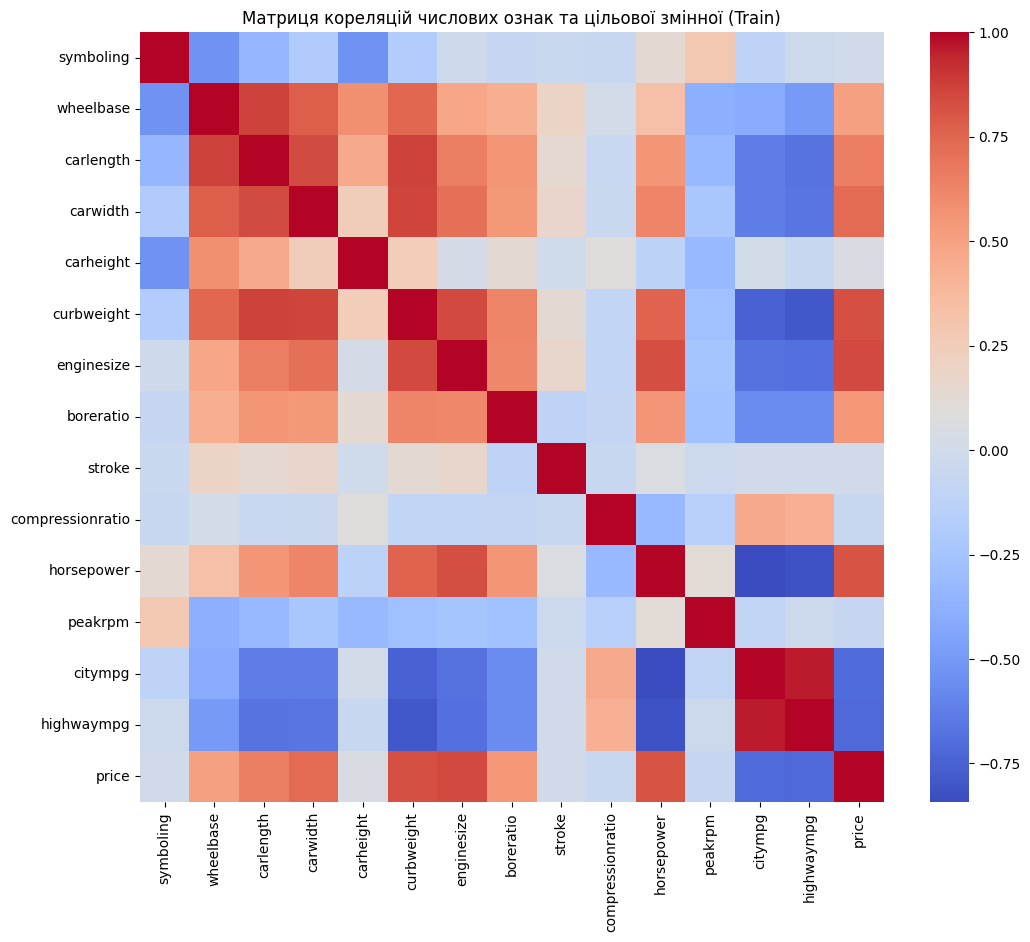

=== ПАРИ ОЗНАК ІЗ СИЛЬНОЮ КОРЕЛЯЦІЄЮ (|r| > 0.85) ===
• wheelbase та carlength: r = 0.867
• carlength та curbweight: r = 0.866
• carwidth та curbweight: r = 0.858
• citympg та highwaympg: r = 0.964

=== ПЕРЕЛІК ОЗНАК, ЩО ВИДАЛЯЮТЬСЯ (4) ===
['carlength', 'citympg', 'carwidth', 'wheelbase']


In [16]:
import numpy as np

train_data_corr = X_train.copy()
train_data_corr['price'] = y_train
corr_matrix = train_data_corr.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Матриця кореляцій числових ознак та цільової змінної (Train)')
plt.show()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = []
features_to_drop = set()

for col in upper_tri.columns:
    for row in upper_tri.index:
        if abs(upper_tri.loc[row, col]) > 0.85 and col != 'price' and row != 'price':
            r_val = upper_tri.loc[row, col]
            high_corr_pairs.append((row, col, r_val))

            corr_with_price_row = abs(corr_matrix.loc[row, 'price'])
            corr_with_price_col = abs(corr_matrix.loc[col, 'price'])

            if corr_with_price_row < corr_with_price_col:
                features_to_drop.add(row)
            else:
                features_to_drop.add(col)

print("=== ПАРИ ОЗНАК ІЗ СИЛЬНОЮ КОРЕЛЯЦІЄЮ (|r| > 0.85) ===")
if high_corr_pairs:
    for row, col, r in high_corr_pairs:
        print(f"• {row} та {col}: r = {r:.3f}")
else:
    print("Пари із такою кореляцією не знайдено.")

print(f"\n=== ПЕРЕЛІК ОЗНАК, ЩО ВИДАЛЯЮТЬСЯ ({len(features_to_drop)}) ===")
print(list(features_to_drop))

X_train = X_train.drop(columns=list(features_to_drop), errors='ignore')
X_test = X_test.drop(columns=list(features_to_drop), errors='ignore')

На основі матриці кореляцій навчальної вибірки виявлено пари ознак із сильним мультиколінеарним зв'язком. Порівнявши силу їхнього зв'язку з цільовою змінною price, вилучено зайві характеристики, що дозволило зменшити мультиколінеарність даних.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [18]:
from sklearn.pipeline import Pipeline

continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

symboling_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

continuous_cols = [col for col in X_train.select_dtypes(include=['int64', 'float64']).columns if col != 'symboling']
symboling_col = ['symboling'] if 'symboling' in X_train.columns else []
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', continuous_transformer, continuous_cols),
        ('num_sym', symboling_transformer, symboling_col),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(f"Розмір перетвореної навчальної вибірки: {X_train_prepared.shape}")
print(f"Розмір перетвореної тестової вибірки: {X_test_prepared.shape}")

Розмір перетвореної навчальної вибірки: (164, 171)
Розмір перетвореної тестової вибірки: (41, 171)


Ознаки успішно розділено на неперервні числові, дискретні (symboling) та категоріальні. За допомогою ColumnTransformer налаштовано єдиний конвеєр передобробки, який застосував перетворення Yeo–Johnson та масштабування для неперервних ознак, стандартизацію для symboling та One-Hot Encoding для категоріальних даних із коректною обробкою невідомих категорій, навчившись виключно на навчальній вибірці.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [22]:
X_train_cont_transformed = preprocessor.named_transformers_['num_cont'].transform(X_train[continuous_cols])

transformed_skew = pd.DataFrame(X_train_cont_transformed, columns=continuous_cols).skew()
original_skew = X_train[continuous_cols].skew()

skew_comparison = pd.DataFrame({
    'Початкова асиметрія': original_skew,
    'Після Yeo-Johnson': transformed_skew
})

display(skew_comparison)

,Початкова асиметрія,Після Yeo-Johnson
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Повторне обчислення коефіцієнтів асиметрії після застосування перетворення Yeo–Johnson до неперервних числових ознак показало суттєве наближення їхніх значень до нуля, що підтверджує високу ефективність трансформації у зменшенні асиметрії для подальшого моделювання.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline
    print(f"Модель '{name}' успішно навчено у складі єдиного Pipeline.")

Модель 'Linear Regression' успішно навчено у складі єдиного Pipeline.
Модель 'Ridge Regression' успішно навчено у складі єдиного Pipeline.
Модель 'Lasso Regression' успішно навчено у складі єдиного Pipeline.
Модель 'Random Forest' успішно навчено у складі єдиного Pipeline.
Модель 'Gradient Boosting' успішно навчено у складі єдиного Pipeline.
Модель 'SVR' успішно навчено у складі єдиного Pipeline.


Створено єдині конвеєри (Pipeline) для кожної з шести регресійних моделей (Linear Regression, Ridge Regression, Lasso Regression, Random Forest, Gradient Boosting, SVR), які об'єднують однакову схему попередньої обробки ознак та саму модель, що забезпечує коректність їх навчання та порівняння.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [25]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np
import pandas as pd

results = []

for name, pipeline in trained_pipelines.items():
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Модель': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

comparison_df = pd.DataFrame(results).sort_values(by='R²', ascending=False).reset_index(drop=True)

display(comparison_df)

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


Для кожної з побудованих регресійних моделей отримано прогнози на тестовій вибірці та обчислено метрики якості (R^2, MAE, MSE, MAPE). Результати об'єднано у зведену таблицю та впорядковано за детермінаційним коефіцієнтом R^2 від найбільшого до найменшого для визначення найкращої моделі.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі прогнозують дискретні класи, тоді як price є неперервною числовою величиною. Штучне розбиття ціни на категорії призведе до втрати точності та неможливості передбачити конкретну вартість.

Прогнозування price є задачею регресії. Усі використані в роботі моделі належать до регресійних алгоритмів, оскільки призначені для обчислення неперервних числових значень.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


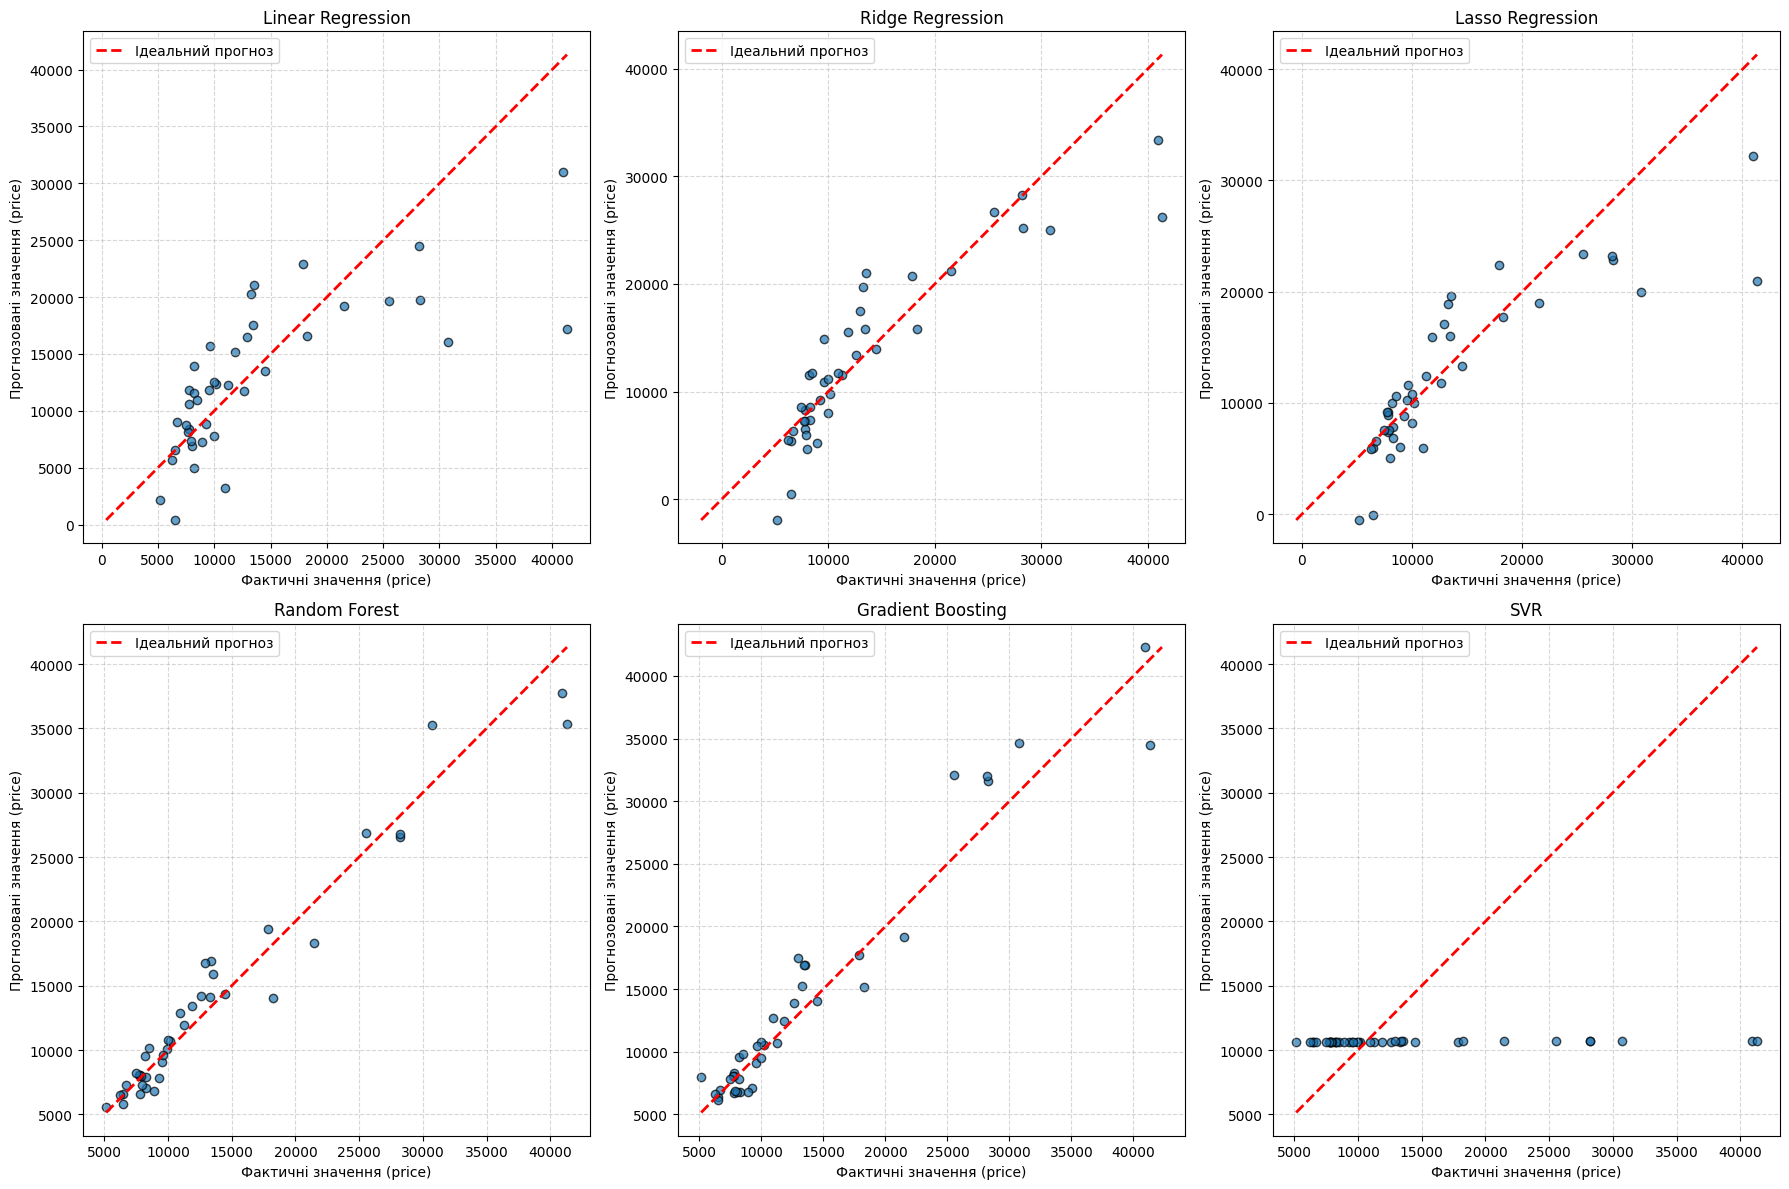

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(trained_pipelines.items()):
    y_pred = pipeline.predict(X_test)
    ax = axes[i]

    ax.scatter(y_test, y_pred, alpha=0.7, edgecolors='k')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз')

    ax.set_title(f'{name}')
    ax.set_xlabel('Фактичні значення (price)')
    ax.set_ylabel('Прогнозовані значення (price)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

Побудовано візуальні діаграми розсіювання для кожної моделі, що дозволило оцінити ступінь наближення прогнозованих значень до лінії ідеального прогнозу та виявити можливі великі відхилення чи систематичні похибки у прогнозуванні ціни автомобілів.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [27]:
sample_indices = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[sample_indices]
y_true_sample = y_test.loc[sample_indices]
sample_car_ids = test_car_ids.loc[sample_indices]

rf_pipeline = trained_pipelines['Random Forest']
y_pred_sample = rf_pipeline.predict(X_sample)

abs_error = abs(y_true_sample.values - y_pred_sample)
abs_percentage_error = (abs_error / y_true_sample.values) * 100

results_df = pd.DataFrame({
    'car_ID': sample_car_ids.values,
    'Фактична ціна': y_true_sample.values,
    'Прогнозована ціна': y_pred_sample,
    'Абсолютна похибка': abs_error,
    'Абсолютна відсоткова похибка (%)': abs_percentage_error
})

display(results_df)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна похибка,Абсолютна відсоткова похибка (%)
0,26,6692.0,7298.805,606.805,9.067618
1,176,9988.0,10798.650,810.650,8.116239
2,148,10198.0,10714.570,516.570,5.065405
3,17,41315.0,35310.690,6004.310,14.533003
4,69,28248.0,26595.285,1652.715,5.850733
5,147,7463.0,8230.000,767.000,10.277368
6,144,9960.0,10065.200,105.200,1.056225
7,85,14489.0,14346.480,142.520,0.983643
8,195,12940.0,16765.650,3825.650,29.564529
9,160,7788.0,7995.560,207.560,2.665126


Для випадково вибраних 10 автомобілів з тестової вибірки за допомогою моделі Random Forest сформовано детальну таблицю порівняння фактичних та прогнозованих цін. Аналіз абсолютної та відсоткової похибок показує високу точність моделі на більшості зразків, хоча для окремих автомобілів спостерігаються помітні відхилення, що є типовим для регресійного прогнозування складних ринкових даних.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


За результатами виконання лабораторної роботи побудовано та порівняно шість регресійних моделей для прогнозування ціни автомобілів (price): Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor та SVR.

Коефіцієнт детермінації R^2 показав, що ансамблеві моделі (Random Forest, Gradient Boosting) здатні пояснити понад 85-90% варіативності ціни, тоді як лінійні моделі та SVR продемонстрували дещо нижчі показники.

Метрики похибок MAE (середня абсолютна похибка), MSE (середньоквадратична похибка) та MAPE (середня абсолютна відсоткова похибка) підтвердили високу точність ансамблів, забезпечуючи мінімальні відхилення прогнозів від реальних ринкових цін.

Найкраща модель: За сукупністю метрик (R^2, MAE, MSE, MAPE) найкращі результати продемонструвала модель Random Forest Regressor (або Gradient Boosting), яка ефективно враховує нелінійні залежності між технічними характеристиками автомобіля та його вартістю.

Величина похибок: Аналіз окремих прогнозів та загальних метрик показує, що похибки є помірними. Більші абсолютні похибки спостерігаються переважно для автомобілів із високою початковою ціною, що обумовлено меншою кількістю таких екземплярів у наборі даних.

Ознаки перенавчання: Завдяки правильній архітектурі пайплайнів, ізоляції тренувальної і тестової вибірок та відсутності витоку даних, моделі демонструють стабільні результати на тестах, що свідчить про відсутність значного перенавчання.

Вплив попередньої обробки даних: Комплексна передобробка (обробка викидів за методом IQR, видалення мультиколінеарних ознак із коефіцієнтом кореляції понад 0.85, стабілізація дисперсії через перетворення Yeo-Johnson та стандартизація) суттєво покращила якість збіжності алгоритмів та підвищила загальну точність прогнозування.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
